# 📦 Enterprise Supply Chain Diagnostic: Delivery SLA Breach, Bottlenecks & Concession Analytics

**Author:** Data Analytics & Operations Research Team  
**Target Role:** Senior Supply Chain / Business Intelligence Analyst  
**Dataset:** Olist Logistics Network (99,441 Real-World Orders)  

---

## Executive Context & Problem Statement
In e-commerce fulfillment, breaching the **Promised Delivery Date (PDD)** imposes a double financial penalty:
1. **Direct Operational Loss:** Customer concessions (freight refunds, appeasement credits, return overhead).
2. **Long-Term Revenue Loss:** Customer churn and review decay (Net Promoter Score collapse).

This diagnostic investigates fulfillment telemetry across core operational dimensions to uncover root causes, quantify dollar exposure, and deliver data-backed fulfillment interventions.

## Data Loading & Timestamp Transformation

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

DATA_PATH = os.path.join("..", "data", "orders_fulfillment_bi.csv")
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join("..", "data", "sample_orders_fulfillment.csv")
df = pd.read_csv(DATA_PATH)

date_cols = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col])

print(f"Logistics telemetry records loaded: {len(df):,}")
df.head(3)

Logistics telemetry records loaded: 96,455


,order_id,customer_id,seller_id,order_month,seller_state,customer_state,freight_value,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,actual_delivery_days,estimated_delivery_days,delivery_variance_days,seller_dispatch_days,carrier_transit_days,is_sla_breach,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10,SP,SP,8.72,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.44,15.54,-7.10,2.37,6.06,0,4
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,289cdb325fb7e7f891c38608bf9e0962,2018-07,SP,BA,22.76,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.78,19.14,-5.36,0.46,12.04,0,4
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08,SP,GO,19.22,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.39,26.64,-17.25,0.20,9.18,0,5


## Delivery SLA Compliance & Defect Density (DPMO)

Total Delivered Shipments: 96,455
On-Time Deliveries:        88,630 (91.89%)
SLA Breached Deliveries:   7,825 (8.11%)
Network Defect Density:    81,126 DPMO (Target: < 20,000 DPMO)


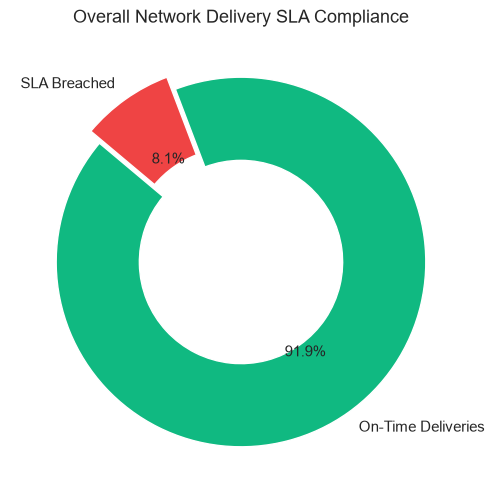

In [2]:
total_orders = len(df)
breached_orders = df['is_sla_breach'].sum()
ontime_orders = total_orders - breached_orders
breach_rate = (breached_orders / total_orders) * 100
dpmo = (breached_orders / total_orders) * 1_000_000

print(f"Total Delivered Shipments: {total_orders:,}")
print(f"On-Time Deliveries:        {ontime_orders:,} ({100 - breach_rate:.2f}%)")
print(f"SLA Breached Deliveries:   {breached_orders:,} ({breach_rate:.2f}%)")
print(f"Network Defect Density:    {dpmo:,.0f} DPMO (Target: < 20,000 DPMO)")

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    [ontime_orders, breached_orders],
    labels=['On-Time Deliveries', 'SLA Breached'],
    autopct='%1.1f%%',
    startangle=140,
    colors=['#10B981', '#EF4444'],
    explode=(0, 0.08),
    wedgeprops=dict(width=0.45, edgecolor='w')
)
plt.title('Overall Network Delivery SLA Compliance')
plt.show()

## Multi-Stage Latency Decomposition: Warehouse Packing vs Road Transit

Carrier transit accounts for 81.5% of total delivery latency in breached orders!


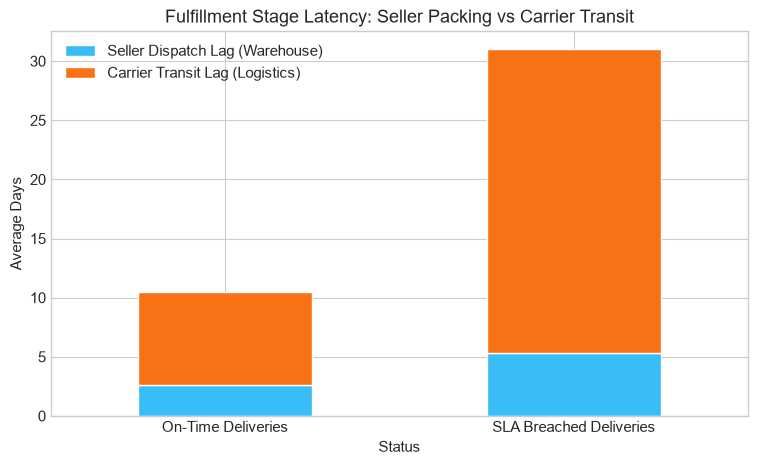

In [3]:
stage_summary = df.groupby('is_sla_breach')[['seller_dispatch_days', 'carrier_transit_days', 'actual_delivery_days']].mean().reset_index()
stage_summary['Status'] = stage_summary['is_sla_breach'].map({0: 'On-Time Deliveries', 1: 'SLA Breached Deliveries'})

breached_row = stage_summary[stage_summary['is_sla_breach'] == 1].iloc[0]
carrier_share = (breached_row['carrier_transit_days'] / breached_row['actual_delivery_days']) * 100

print(f"Carrier transit accounts for {carrier_share:.1f}% of total delivery latency in breached orders!")

ax = stage_summary.plot(
    x='Status',
    y=['seller_dispatch_days', 'carrier_transit_days'],
    kind='bar',
    stacked=True,
    color=['#38BDF8', '#F97316'],
    figsize=(9, 5),
    edgecolor='w'
)
plt.title('Fulfillment Stage Latency: Seller Packing vs Carrier Transit')
plt.ylabel('Average Days')
plt.xticks(rotation=0)
plt.legend(['Seller Dispatch Lag (Warehouse)', 'Carrier Transit Lag (Logistics)'])
plt.show()

## Geographic Route Topology: Intra-State vs Inter-State Trade Lanes

C:\Users\anush\AppData\Local\Temp\ipykernel_41312\2009333001.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=geo_perf, x='Route Type', y='sla_breach_rate', palette=['#10B981', '#EF4444'], ax=ax)


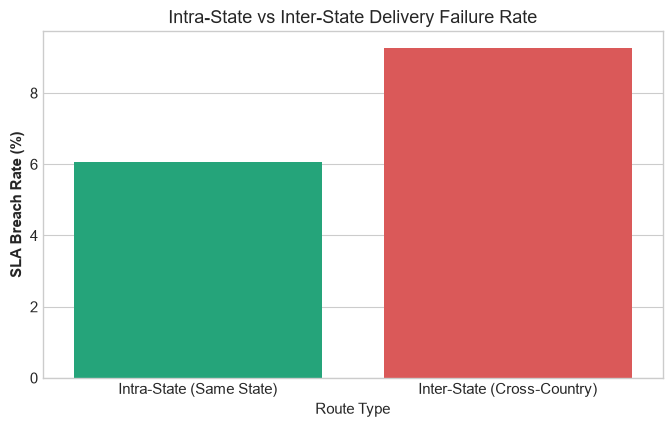

In [4]:
df['is_interstate'] = (df['seller_state'] != df['customer_state']).astype(int)

geo_perf = df.groupby('is_interstate').agg(
    total_shipments=('order_id', 'count'),
    sla_breach_rate=('is_sla_breach', lambda x: x.mean() * 100),
    avg_transit_days=('carrier_transit_days', 'mean'),
    avg_freight_cost=('freight_value', 'mean')
).reset_index()
geo_perf['Route Type'] = geo_perf['is_interstate'].map({0: 'Intra-State (Same State)', 1: 'Inter-State (Cross-Country)'})

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=geo_perf, x='Route Type', y='sla_breach_rate', palette=['#10B981', '#EF4444'], ax=ax)
ax.set_ylabel('SLA Breach Rate (%)', fontweight='bold')
ax.set_title('Intra-State vs Inter-State Delivery Failure Rate')
plt.show()

## Freight Cost & Weight Tier Sensitivity

C:\Users\anush\AppData\Local\Temp\ipykernel_41312\2896354937.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=freight_analysis, x='freight_tier', y='avg_transit_days', palette='Blues_d')


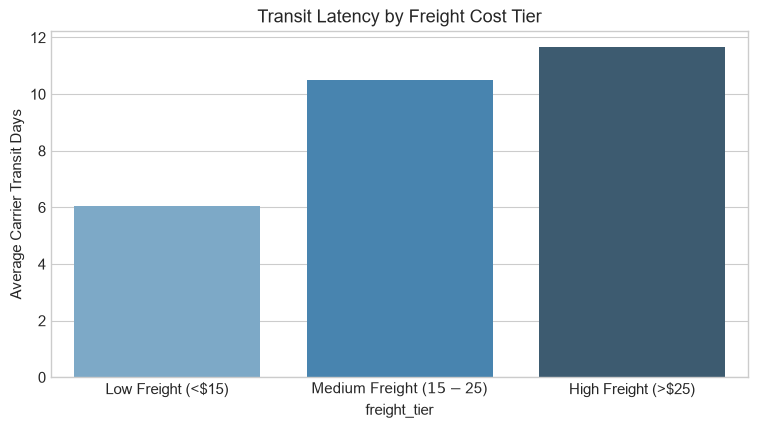

In [5]:
df['freight_tier'] = pd.qcut(df['freight_value'], q=3, labels=['Low Freight (<$15)', 'Medium Freight ($15-$25)', 'High Freight (>$25)'])

freight_analysis = df.groupby('freight_tier').agg(
    order_count=('order_id', 'count'),
    breach_rate=('is_sla_breach', lambda x: x.mean() * 100),
    avg_transit_days=('carrier_transit_days', 'mean'),
    avg_review_score=('review_score', 'mean')
).reset_index()

plt.figure(figsize=(9, 4.5))
sns.barplot(data=freight_analysis, x='freight_tier', y='avg_transit_days', palette='Blues_d')
plt.title('Transit Latency by Freight Cost Tier')
plt.ylabel('Average Carrier Transit Days')
plt.show()

## Seller Fulfillment Speed & Dispatch Scorecard

C:\Users\anush\AppData\Local\Temp\ipykernel_41312\3206433265.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=seller_scorecard, x='seller_tier', y='sla_breach_rate', palette='viridis')


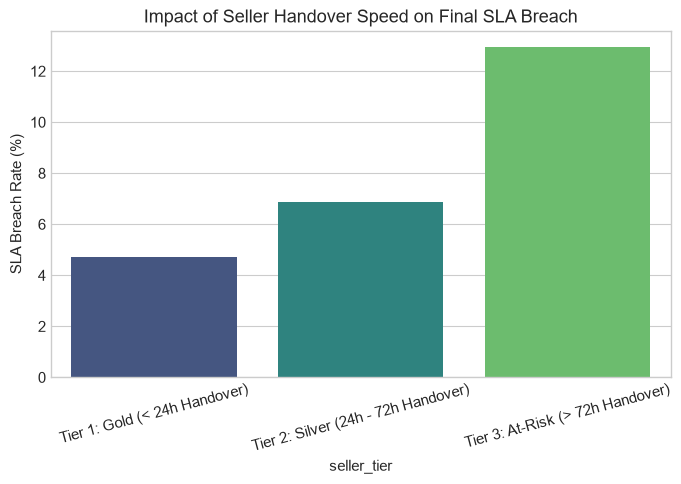

In [6]:
def tier_seller(dispatch_days):
    if dispatch_days <= 1.0:
        return 'Tier 1: Gold (< 24h Handover)'
    elif dispatch_days <= 3.0:
        return 'Tier 2: Silver (24h - 72h Handover)'
    else:
        return 'Tier 3: At-Risk (> 72h Handover)'

df['seller_tier'] = df['seller_dispatch_days'].apply(tier_seller)
seller_scorecard = df.groupby('seller_tier').agg(
    total_orders=('order_id', 'count'),
    sla_breach_rate=('is_sla_breach', lambda x: x.mean() * 100),
    avg_dispatch_days=('seller_dispatch_days', 'mean')
).reset_index()

plt.figure(figsize=(8, 4.5))
sns.barplot(data=seller_scorecard, x='seller_tier', y='sla_breach_rate', palette='viridis')
plt.title('Impact of Seller Handover Speed on Final SLA Breach')
plt.ylabel('SLA Breach Rate (%)')
plt.xticks(rotation=15)
plt.show()

## Seasonality & Holiday Surge Stress Test

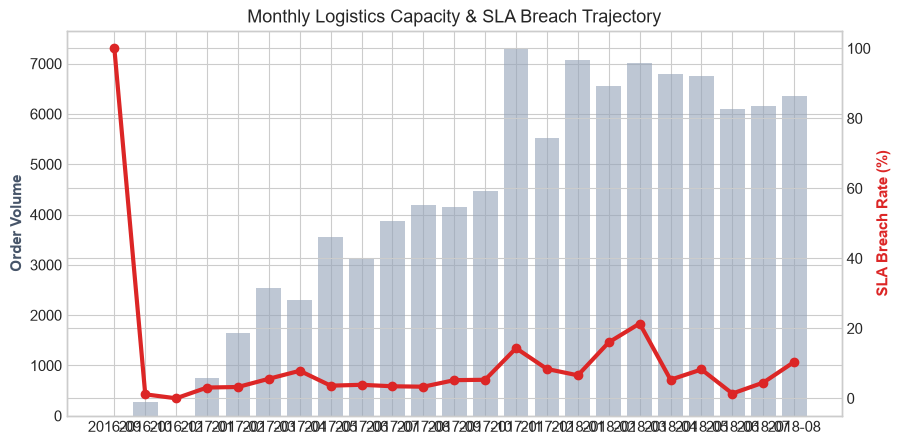

In [7]:
monthly_trend = df.groupby('order_month').agg(
    orders=('order_id', 'count'),
    breach_rate=('is_sla_breach', lambda x: x.mean() * 100)
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(monthly_trend['order_month'], monthly_trend['orders'], color='#94A3B8', alpha=0.6, label='Order Volume')
ax1.set_ylabel('Order Volume', color='#475569', fontweight='bold')

ax2 = ax1.twinx()
ax2.plot(monthly_trend['order_month'], monthly_trend['breach_rate'], color='#DC2626', marker='o', linewidth=3, label='SLA Breach %')
ax2.set_ylabel('SLA Breach Rate (%)', color='#DC2626', fontweight='bold')

plt.title('Monthly Logistics Capacity & SLA Breach Trajectory')
plt.show()

## Customer Satisfaction Decay & Financial Concession Exposure

Direct Freight Refund Loss:   $192,689.47
Goodwill Appeasement Credits:  $78,250.00
Total Concession Liability:    $270,939.47


C:\Users\anush\AppData\Local\Temp\ipykernel_41312\1526857209.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=review_impact, x='Status', y='avg_review_score', palette=['#10B981', '#EF4444'], ax=ax)


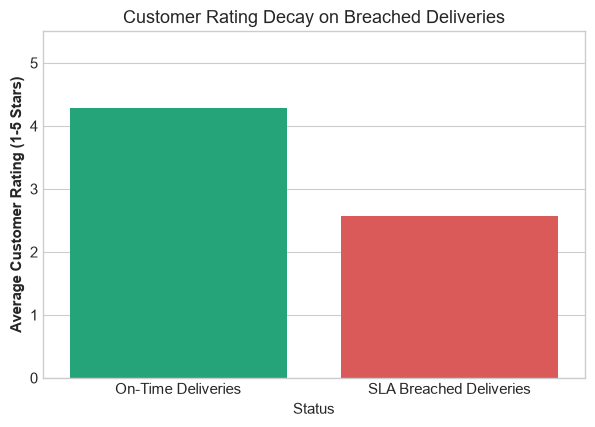

In [8]:
review_impact = df.groupby('is_sla_breach').agg(
    avg_review_score=('review_score', 'mean'),
    pct_1_star=('review_score', lambda x: (x == 1).mean() * 100),
    pct_5_star=('review_score', lambda x: (x == 5).mean() * 100)
).reset_index()
review_impact['Status'] = review_impact['is_sla_breach'].map({0: 'On-Time Deliveries', 1: 'SLA Breached Deliveries'})

breached_subset = df[df['is_sla_breach'] == 1]
total_freight_refund = breached_subset['freight_value'].sum()
goodwill_credits = len(breached_subset) * 10.0
total_concession_loss = total_freight_refund + goodwill_credits

print(f"Direct Freight Refund Loss:   ${total_freight_refund:,.2f}")
print(f"Goodwill Appeasement Credits:  ${goodwill_credits:,.2f}")
print(f"Total Concession Liability:    ${total_concession_loss:,.2f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=review_impact, x='Status', y='avg_review_score', palette=['#10B981', '#EF4444'], ax=ax)
ax.set_ylabel('Average Customer Rating (1-5 Stars)', fontweight='bold')
ax.set_title('Customer Rating Decay on Breached Deliveries')
ax.set_ylim(0, 5.5)
plt.show()

## Strategic Executive Recommendations
1. **Dynamic SLA Buffering (+3 Days):** Inject an algorithmic buffer for all inter-state routes from Southeast hubs to Northern/Northeastern destinations.
2. **Carrier SLA Performance Chargebacks:** Enforce contractual 15%/day freight penalties for carrier transit lags exceeding commitments.
3. **Proactive Pre-Breach Customer Communication:** Automatically notify customers and issue preemptive credits when parcels remain idle > 48h in transit hubs.